# Teen Stress Level Prediction - Main Pipeline

End-to-end run: EDA, split, preprocessing, baselines, tuning, final test, explainability.

## Contents
1. Setup
2. Load data
3. Data quality check
4. Target and correlations
5. Train / val / test split
6. Preprocessing and scoring helper
7. Baseline models
8. Tuning (Random Forest)
9. Final model, test score, and save
10. Explainability
11. Summary

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42

## 2. Load data

In [2]:
df = pd.read_csv("../data/mental_health_analysis.csv")
df.columns = df.columns.str.lower().str.replace(" ", "_")

print(f"Rows: {len(df)}, Cols: {len(df.columns)}")
df.head(3)

Rows: 5000, Cols: 11


,user_id,age,gender,social_media_hours,exercise_hours,sleep_hours,screen_time_hours,survey_stress_score,wearable_stress_score,support_system,academic_performance
0,1,16,F,9.654486,2.458001,5.198926,8.158189,3,0.288962,Moderate,Excellent
1,2,17,M,9.158143,0.392095,8.866097,5.151993,5,0.409446,Moderate,Good
2,3,15,M,5.028755,0.520119,4.943095,9.209325,2,0.423837,Moderate,Poor


## 3. Data quality check

In [3]:
# Missing values, duplicates, IDs
df.info()
print("Duplicates:", df.duplicated().sum())
print("Unique user_id:", df["user_id"].nunique())
print(df.isnull().sum()[df.isnull().sum() > 0])  # prints nothing if no missing

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   user_id                5000 non-null   int64  
 1   age                    5000 non-null   int64  
 2   gender                 5000 non-null   str    
 3   social_media_hours     5000 non-null   float64
 4   exercise_hours         5000 non-null   float64
 5   sleep_hours            5000 non-null   float64
 6   screen_time_hours      5000 non-null   float64
 7   survey_stress_score    5000 non-null   int64  
 8   wearable_stress_score  5000 non-null   float64
 9   support_system         5000 non-null   str    
 10  academic_performance   5000 non-null   str    
dtypes: float64(5), int64(3), str(3)
memory usage: 488.3 KB
Duplicates: 0
Unique user_id: 5000
Series([], dtype: int64)


In [4]:
# One-line stats for numeric columns
df.describe().round(2)
print(df[["gender", "support_system", "academic_performance"]].nunique())

gender                  2
support_system          3
academic_performance    4
dtype: int64


## 4. Target and correlations
Target is survey_stress_score (1-5). wearable_stress_score is dropped later: it would not be known at prediction time, so keeping it would be leakage.

survey_stress_score
1     981
2    1004
3     987
4    1011
5    1017
Name: count, dtype: int64
survey_stress_score
1    19.6
2    20.1
3    19.7
4    20.2
5    20.3
Name: proportion, dtype: float64


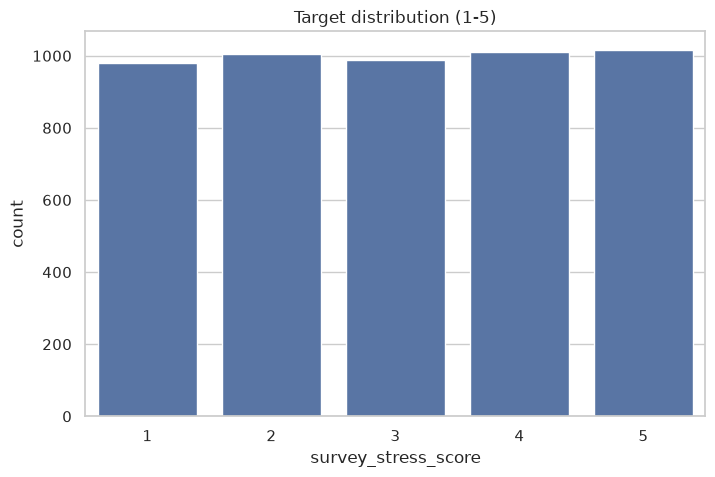

In [5]:
# Target balance: about 20% per class
print(df["survey_stress_score"].value_counts().sort_index())
print((df["survey_stress_score"].value_counts(normalize=True).sort_index() * 100).round(1))

sns.countplot(data=df, x="survey_stress_score")
plt.title("Target distribution (1-5)")
plt.xlabel("survey_stress_score")
plt.ylabel("count")
plt.show()

                      age  social_media_hours  exercise_hours  sleep_hours  \
age                  1.00               -0.00            0.02        -0.01   
social_media_hours  -0.00                1.00           -0.02        -0.01   
exercise_hours       0.02               -0.02            1.00         0.02   
sleep_hours         -0.01               -0.01            0.02         1.00   
screen_time_hours    0.00                0.01           -0.01        -0.00   
survey_stress_score  0.01               -0.00            0.00         0.02   

                     screen_time_hours  survey_stress_score  
age                               0.00                 0.01  
social_media_hours                0.01                -0.00  
exercise_hours                   -0.01                 0.00  
sleep_hours                      -0.00                 0.02  
screen_time_hours                 1.00                -0.00  
survey_stress_score              -0.00                 1.00  
wearable vs survey 

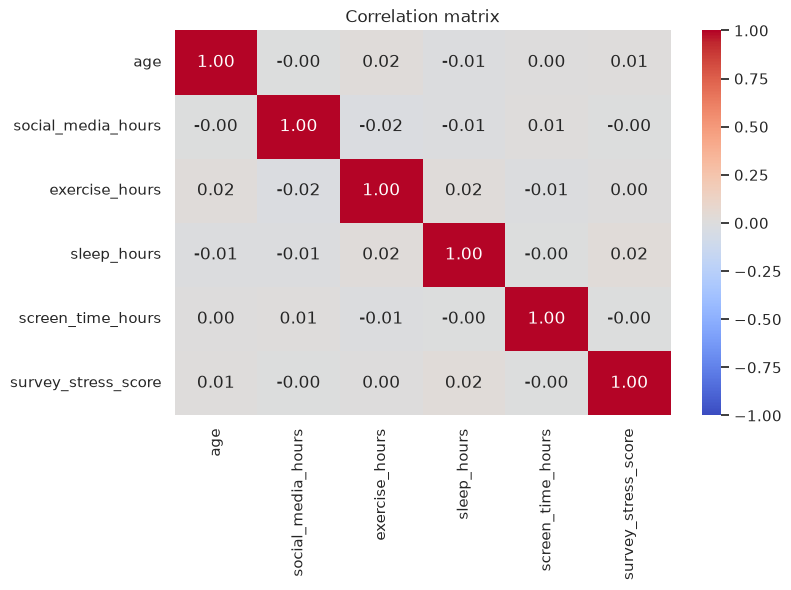

In [6]:
# Correlations are all near zero -> weak signal
num_cols = ["age", "social_media_hours", "exercise_hours", "sleep_hours", "screen_time_hours"]
print(df[num_cols + ["survey_stress_score"]].corr().round(2))
print("wearable vs survey corr:", round(df["survey_stress_score"].corr(df["wearable_stress_score"]), 4))

sns.heatmap(df[num_cols + ["survey_stress_score"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

## 5. Train / val / test split
60% train, 20% val, 20% test. Stratified so each split keeps the same class balance. Labels 1-5 are shifted to 0-4 for XGBoost.

In [7]:
from sklearn.model_selection import train_test_split

target_col = "survey_stress_score"
num_features = ["age", "social_media_hours", "exercise_hours", "sleep_hours", "screen_time_hours"]
cat_features = ["gender", "support_system", "academic_performance"]

X = df.drop(columns=["user_id", "wearable_stress_score", target_col])
y = (df[target_col] - 1).astype(int)  # 0-4

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=RANDOM_STATE)

print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")
pd.DataFrame({
    "full": y.value_counts(normalize=True).sort_index(),
    "train": y_train.value_counts(normalize=True).sort_index(),
    "val": y_val.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
}).round(3)

Train: 3000, Val: 1000, Test: 1000


,full,train,val,test
survey_stress_score,,,,
0,0.196,0.196,0.196,0.196
1,0.201,0.201,0.201,0.201
2,0.197,0.197,0.197,0.198
3,0.202,0.202,0.202,0.202
4,0.203,0.203,0.204,0.203


## 6. Preprocessing and scoring helper
Scale numbers, one-hot encode categories. Primary metric is macro F1 (equal weight per stress level).

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])
print("Example output shape:", preprocessor.fit_transform(X_train).shape)

Example output shape: (3000, 14)


In [9]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

LABELS = ["Lvl 1", "Lvl 2", "Lvl 3", "Lvl 4", "Lvl 5"]

def score_model(y_true, y_pred, name="Model", show_plot=True):
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    print(f"{name} | acc={acc:.3f} macro_f1={macro_f1:.3f}")
    print(classification_report(y_true, y_pred, target_names=LABELS))
    if show_plot:
        ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=LABELS)
        plt.title(f"Confusion matrix - {name}")
        plt.grid(False)
        plt.show()
    return {"model": name, "acc": round(acc, 4), "macro_f1": round(macro_f1, 4)}

## 7. Baseline models
Same preprocessing for all four. Ranked by val macro F1.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "LogReg": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1,
        objective="multi:softprob", num_class=5, random_state=RANDOM_STATE),
}

results = []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    pipe.fit(X_train, y_train)
    results.append(score_model(y_val, pipe.predict(X_val), name=name, show_plot=False))

comp = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
comp

LogReg | acc=0.209 macro_f1=0.204
              precision    recall  f1-score   support

       Lvl 1       0.19      0.19      0.19       196
       Lvl 2       0.17      0.14      0.15       201
       Lvl 3       0.22      0.18      0.20       197
       Lvl 4       0.24      0.35      0.29       202
       Lvl 5       0.19      0.18      0.19       204

    accuracy                           0.21      1000
   macro avg       0.20      0.21      0.20      1000
weighted avg       0.21      0.21      0.20      1000

Tree | acc=0.194 macro_f1=0.194
              precision    recall  f1-score   support

       Lvl 1       0.18      0.17      0.17       196
       Lvl 2       0.17      0.17      0.17       201
       Lvl 3       0.21      0.19      0.20       197
       Lvl 4       0.23      0.23      0.23       202
       Lvl 5       0.18      0.20      0.19       204

    accuracy                           0.19      1000
   macro avg       0.19      0.19      0.19      1000
weighted av

Forest | acc=0.189 macro_f1=0.189
              precision    recall  f1-score   support

       Lvl 1       0.18      0.21      0.19       196
       Lvl 2       0.18      0.18      0.18       201
       Lvl 3       0.19      0.18      0.18       197
       Lvl 4       0.19      0.16      0.17       202
       Lvl 5       0.21      0.22      0.21       204

    accuracy                           0.19      1000
   macro avg       0.19      0.19      0.19      1000
weighted avg       0.19      0.19      0.19      1000



XGBoost | acc=0.200 macro_f1=0.200
              precision    recall  f1-score   support

       Lvl 1       0.22      0.20      0.21       196
       Lvl 2       0.17      0.18      0.18       201
       Lvl 3       0.20      0.20      0.20       197
       Lvl 4       0.22      0.25      0.23       202
       Lvl 5       0.18      0.18      0.18       204

    accuracy                           0.20      1000
   macro avg       0.20      0.20      0.20      1000
weighted avg       0.20      0.20      0.20      1000



,model,acc,macro_f1
0,LogReg,0.209,0.2040
1,XGBoost,0.200,0.1997
2,Tree,0.194,0.1938
3,Forest,0.189,0.1886


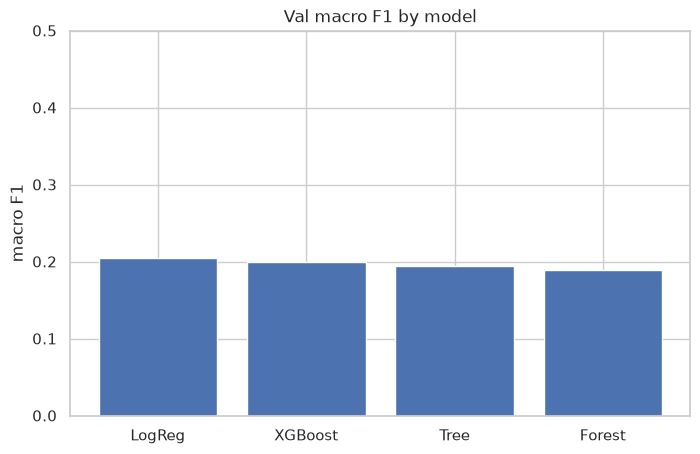

In [11]:
plt.bar(comp["model"], comp["macro_f1"])
plt.title("Val macro F1 by model")
plt.ylabel("macro F1")
plt.ylim(0, 0.5)
plt.show()

## 8. Tuning (Random Forest)
Small grid, 5-fold CV on train only. Compares train vs val to spot overfitting.

In [12]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

grid = GridSearchCV(
    Pipeline([("prep", preprocessor),
              ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
    {"clf__n_estimators": [100, 200],
     "clf__max_depth": [None, 10, 20],
     "clf__min_samples_split": [2, 5]},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best:", grid.best_params_)
print(f"Best CV macro F1: {grid.best_score_:.3f}")

train_f1 = f1_score(y_train, grid.predict(X_train), average="macro")
val_f1 = f1_score(y_val, grid.predict(X_val), average="macro")
print(f"Train={train_f1:.3f} Val={val_f1:.3f} Gap={train_f1 - val_f1:.3f}")
print("Overfit" if train_f1 - val_f1 > 0.10 else "Gap OK")

Best: {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
Best CV macro F1: 0.204
Train=1.000 Val=0.193 Gap=0.807
Overfit


## 9. Final model, test score, and save
Tuned forest memorizes train (F1 near 1.0) but stays at chance on val (about 0.20). LogReg generalizes the same with no overfit, so it is the final model: refit on train+val, scored once on locked test.

LogReg final (test) | acc=0.215 macro_f1=0.211
              precision    recall  f1-score   support

       Lvl 1       0.21      0.23      0.22       196
       Lvl 2       0.24      0.18      0.21       201
       Lvl 3       0.19      0.19      0.19       198
       Lvl 4       0.24      0.33      0.28       202
       Lvl 5       0.18      0.14      0.16       203

    accuracy                           0.21      1000
   macro avg       0.21      0.22      0.21      1000
weighted avg       0.21      0.21      0.21      1000



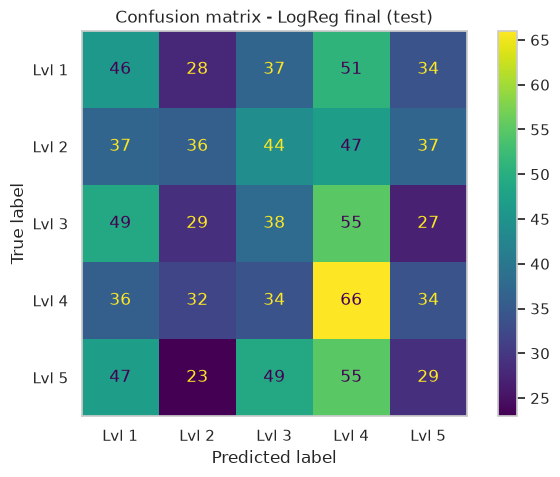

{'model': 'LogReg final (test)', 'acc': 0.215, 'macro_f1': 0.2114}


In [13]:
final = Pipeline([("prep", preprocessor),
                ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
final.fit(X_train_full, y_train_full)

test_pred = final.predict(X_test)
test_metrics = score_model(y_test, test_pred, name="LogReg final (test)")
print(test_metrics)

In [14]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump(final, "../models/final_pipeline.joblib")
joblib.dump({"metrics": test_metrics}, "../models/final_metadata.joblib")
print("Saved to ../models/")

Saved to ../models/


## 10. Explainability
Permutation importance: shuffle one column, see how much val macro F1 drops.

                feature      drop
0  academic_performance  0.004890
1                   age  0.004285
2        exercise_hours  0.002587
3                gender  0.001497
4     screen_time_hours  0.000046
5    social_media_hours -0.000028
6        support_system -0.003399
7           sleep_hours -0.006443


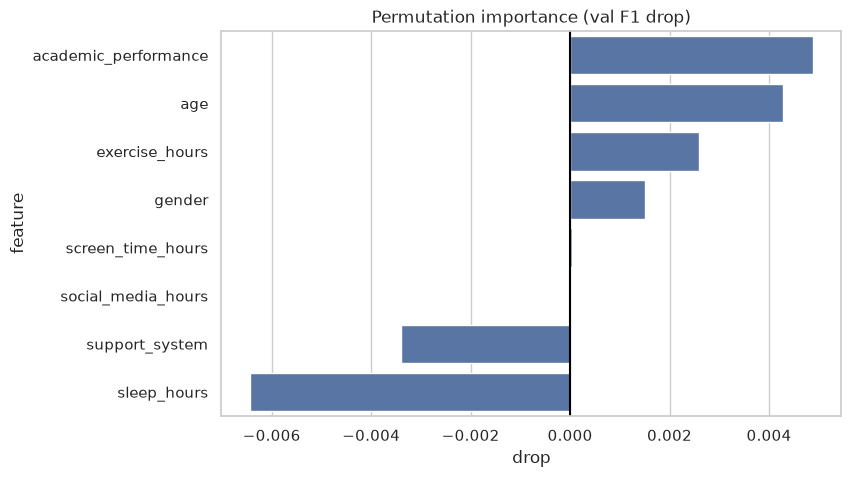

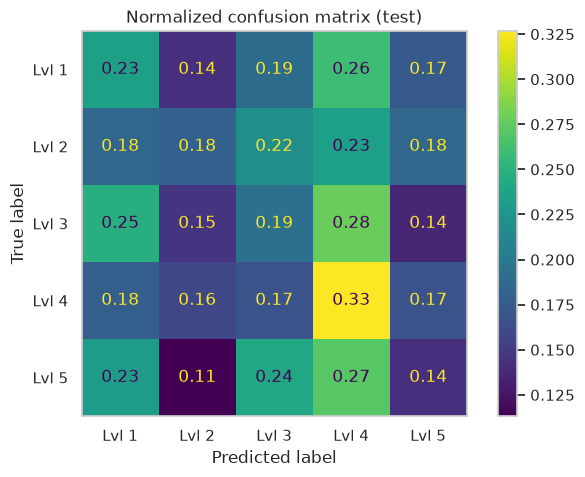

In [15]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final, X_val, y_val, n_repeats=10,
                              scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"feature": X_val.columns, "drop": perm.importances_mean})
imp = imp.sort_values("drop", ascending=False).reset_index(drop=True)
print(imp)

sns.barplot(data=imp, x="drop", y="feature")
plt.title("Permutation importance (val F1 drop)")
plt.axvline(0, color="black")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=LABELS, normalize="true")
plt.title("Normalized confusion matrix (test)")
plt.grid(False)
plt.show()

## 11. Summary
- Split 60/20/20 stratified, macro F1 as main metric.
- All models score about 0.19-0.21 (chance = 0.20): lifestyle columns carry almost no signal here.
- Tuned forest overfits (train F1 near 1.0, val at chance), so plain LogReg is shipped.
- Artifacts in ../models/ feed src/train.py, src/predict.py and the app.
- Next: richer features, ordinal models, do not re-tune on test.